In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("../data/processed/landmarks.csv")

print("Shape:", df.shape)
print("Classes:", df["label"].nunique())
df.head()

Shape: (2727, 66)
Classes: 36


,label,signer_id,filename,f0,f1,f2,f3,f4,f5,f6,...,f53,f54,f55,f56,f57,f58,f59,f60,f61,f62
0,1-Hay,s0251,s0251-10hay.jpg,0.0,0.0,0.0,0.144057,-0.696173,-0.046720,0.478123,...,-0.447511,1.054861,0.101863,-0.502622,0.969267,-0.009833,-0.403517,0.802021,-0.035178,-0.308149
1,1-Hay,s0252,s0252-10hay.jpg,0.0,0.0,0.0,0.002862,-0.521564,0.121297,0.114996,...,-0.358662,0.855219,-0.409095,-0.287891,0.750940,-0.342864,-0.112112,0.622086,-0.295576,0.031359
2,1-Hay,s0253,s0253-10hay.jpg,0.0,0.0,0.0,0.206797,-0.762612,-0.045245,0.648133,...,-0.435521,1.057891,0.347057,-0.476490,0.969290,0.210020,-0.367453,0.815299,0.191260,-0.263399
3,1-Hay,s0254,s0254-10hay.jpg,0.0,0.0,0.0,0.364359,-0.612799,-0.124997,0.897794,...,-0.612427,1.071940,1.122048,-0.730447,1.032419,0.901794,-0.615665,0.844064,0.755925,-0.490481
4,1-Hay,s0255,s0255-10hay.jpg,0.0,0.0,0.0,0.158055,-0.737145,-0.027868,0.540961,...,-0.428798,0.964727,0.187479,-0.415738,0.902752,0.045193,-0.299164,0.784328,-0.024990,-0.207970


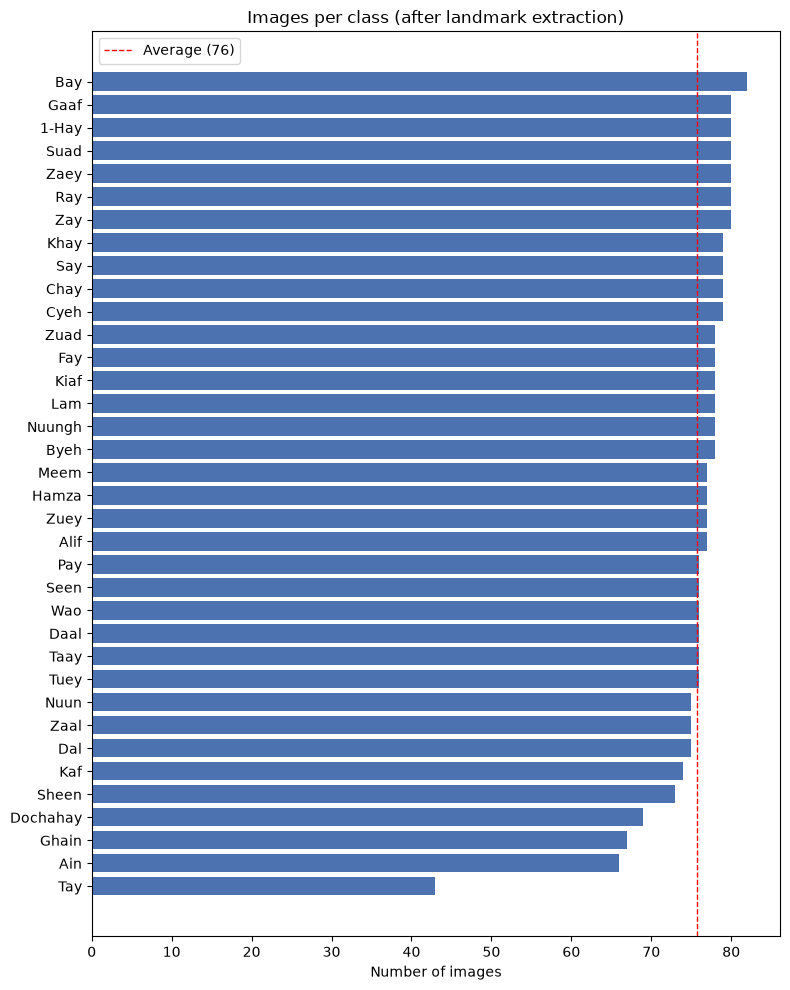

Sabse kam: Tay -> 43
Sabse zyada: Bay -> 82
Average: 75.8


In [2]:
class_counts = df["label"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(class_counts.index, class_counts.values, color="#4C72B0")
ax.set_xlabel("Number of images")
ax.set_title("Images per class (after landmark extraction)")
ax.axvline(class_counts.mean(), color="red", linestyle="--", linewidth=1, label=f"Average ({class_counts.mean():.0f})")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/01_class_distribution.png", dpi=150)
plt.show()

print("Sabse kam:", class_counts.idxmin(), "->", class_counts.min())
print("Sabse zyada:", class_counts.idxmax(), "->", class_counts.max())
print("Average:", round(class_counts.mean(), 1))

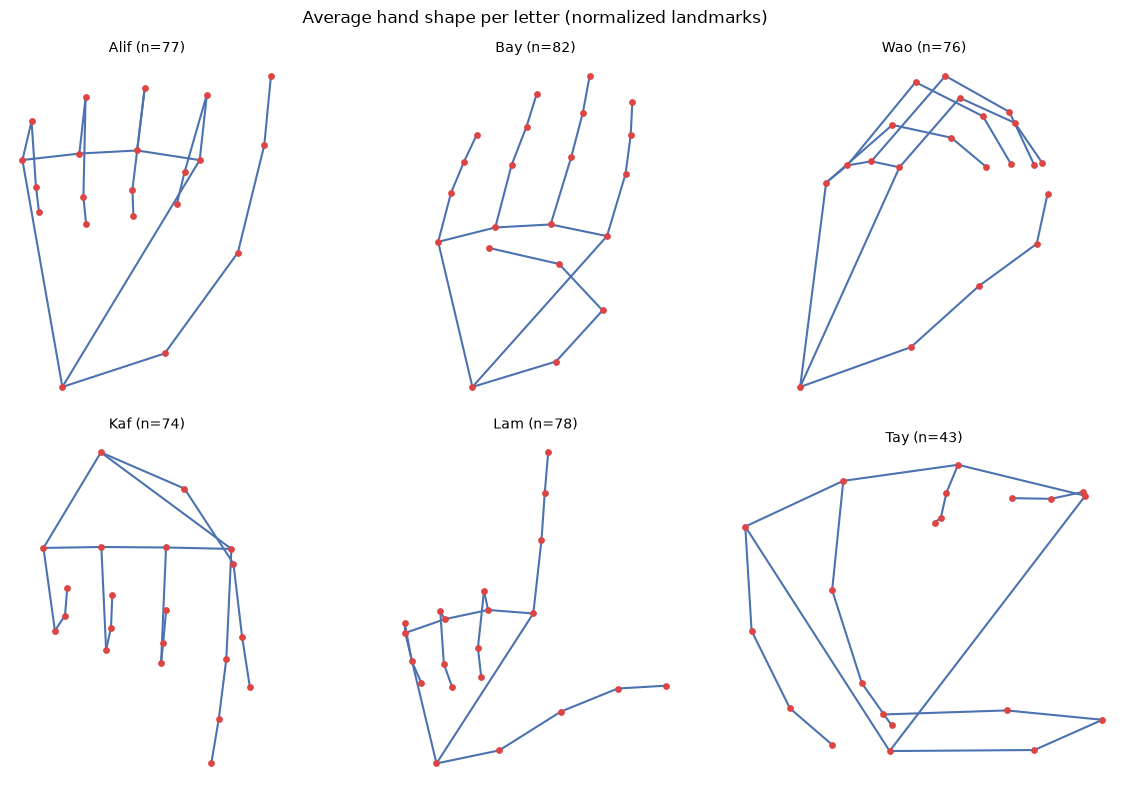

In [3]:
# MediaPipe ka skeleton (kaunsa point kis se juda hai), Step 29 wale diagram jaisa
connections = [
    (0,1),(1,2),(2,3),(3,4),        # thumb
    (0,5),(5,6),(6,7),(7,8),        # index
    (5,9),(9,10),(10,11),(11,12),   # middle
    (9,13),(13,14),(14,15),(15,16), # ring
    (13,17),(17,18),(18,19),(19,20),# pinky
    (0,17),                          # palm base
]

sample_letters = ["Alif", "Bay", "Wao", "Kaf", "Lam", "Tay"]
feature_cols = [f"f{i}" for i in range(63)]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for ax, letter in zip(axes, sample_letters):
    subset = df[df["label"] == letter]
    avg = subset[feature_cols].mean().values.reshape(21, 3)
    xs, ys = avg[:, 0], avg[:, 1]

    for a, b in connections:
        ax.plot([xs[a], xs[b]], [ys[a], ys[b]], color="#4C72B0", linewidth=1.5)
    ax.scatter(xs, ys, color="#DD4444", s=15, zorder=3)

    ax.set_title(f"{letter} (n={len(subset)})", fontsize=10)
    ax.invert_yaxis()  # image coordinates me y neeche ki taraf badhta hai
    ax.set_aspect("equal")
    ax.axis("off")

plt.suptitle("Average hand shape per letter (normalized landmarks)")
plt.tight_layout()
plt.savefig("../reports/figures/02_average_hand_shapes.png", dpi=150)
plt.show()

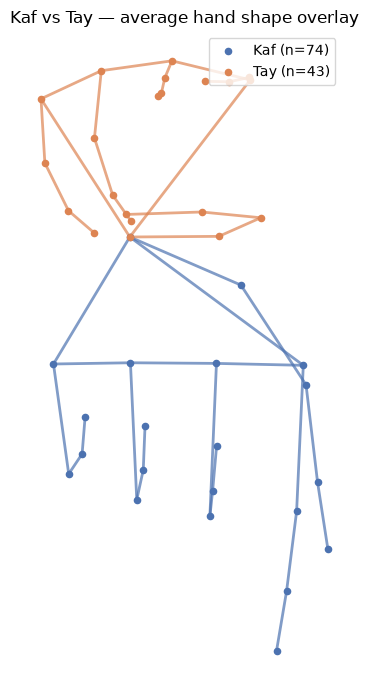

In [4]:
letter1, letter2 = "Kaf", "Tay"

fig, ax = plt.subplots(figsize=(7, 7))

for letter, color in [(letter1, "#4C72B0"), (letter2, "#DD8452")]:
    subset = df[df["label"] == letter]
    avg = subset[feature_cols].mean().values.reshape(21, 3)
    xs, ys = avg[:, 0], avg[:, 1]

    for a, b in connections:
        ax.plot([xs[a], xs[b]], [ys[a], ys[b]], color=color, linewidth=2, alpha=0.7)
    ax.scatter(xs, ys, color=color, s=20, zorder=3, label=f"{letter} (n={len(subset)})")

ax.invert_yaxis()
ax.set_aspect("equal")
ax.axis("off")
ax.legend(loc="upper right")
ax.set_title(f"{letter1} vs {letter2} — average hand shape overlay")

plt.tight_layout()
plt.savefig("../reports/figures/03_similar_letters_overlay.png", dpi=150)
plt.show()

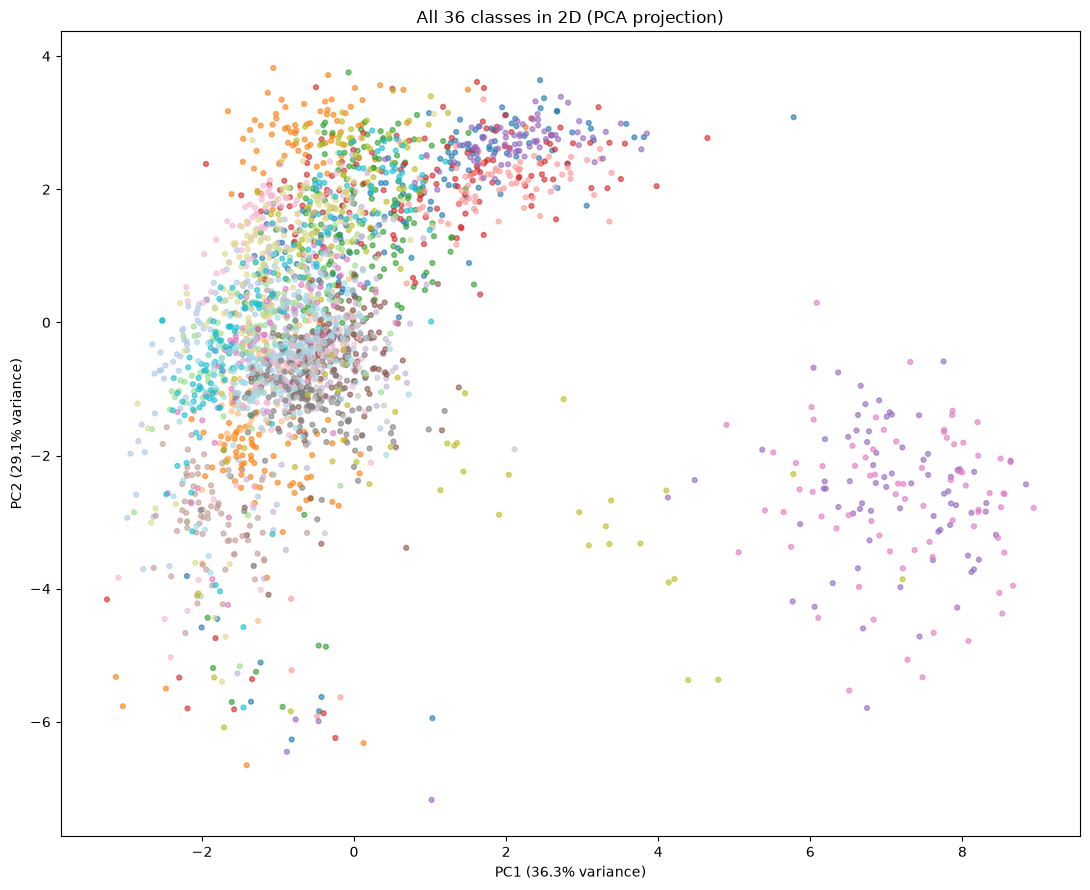

In 2 dimensions me kitni maloomat (variance) bachi hai: 65.4 %


In [5]:
from sklearn.decomposition import PCA

X = df[feature_cols].values
y = df["label"].values

pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(11, 9))
scatter = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=pd.factorize(y)[0], cmap="tab20", s=12, alpha=0.6)

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.set_title("All 36 classes in 2D (PCA projection)")

plt.tight_layout()
plt.savefig("../reports/figures/04_pca_all_classes.png", dpi=150)
plt.show()

print("In 2 dimensions me kitni maloomat (variance) bachi hai:",
      round(pca.explained_variance_ratio_[:2].sum() * 100, 1), "%")